# 🫁 DenseNet for Chest X-Ray Classification
### Detecting Pneumonia from X-Ray Images using Dense Connections

**Idea:** Instead of ResNet's *skip connections* (add), DenseNet uses *dense connections* (concatenate).  
Every layer receives feature maps from **all** previous layers → maximum feature reuse, fewer parameters.

```
ResNet:   x → H1 → H1+x → H2 → H2+(H1+x) → ...
DenseNet: x → H1 → H2(x, H1) → H3(x, H1, H2) → ...
```

**Dataset:** Chest X-Ray Images (Pneumonia) — Kaggle  
**Classes:** NORMAL vs PNEUMONIA  
**Model:** DenseNet-121 (pretrained on ImageNet, fine-tuned)


In [ ]:
# If running locally with uv:
# uv add tensorflow matplotlib seaborn scikit-learn pillow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

from PIL import Image
import os, random

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU available: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow version: 2.19.0
GPU available: False


In [ ]:
# ─────────────────────────────────────────────
#  DenseLayer: BN → ReLU → Conv (bottleneck)
# ─────────────────────────────────────────────
def dense_layer(x, growth_rate):
    """
    Single DenseNet layer.
    Input x: concatenation of all previous feature maps.
    Output : growth_rate new feature maps, concatenated back to x.
    """
    # Bottleneck 1x1
    out = layers.BatchNormalization()(x)
    out = layers.ReLU()(out)
    out = layers.Conv2D(4 * growth_rate, kernel_size=1, use_bias=False)(out)
    # 3x3 conv
    out = layers.BatchNormalization()(out)
    out = layers.ReLU()(out)
    out = layers.Conv2D(growth_rate, kernel_size=3, padding='same', use_bias=False)(out)
    # KEY: concatenate — every layer receives all previous feature maps
    return layers.Concatenate()([x, out])


# ─────────────────────────────────────────────
#  DenseBlock: stack of dense_layers
# ─────────────────────────────────────────────
def dense_block(x, num_layers, growth_rate):
    """Stack num_layers DenseLayers. Channels grow by growth_rate each step."""
    for _ in range(num_layers):
        x = dense_layer(x, growth_rate)
    return x


# ─────────────────────────────────────────────
#  Transition Layer: compress channels between blocks
# ─────────────────────────────────────────────
def transition_layer(x, compression=0.5):
    """Reduce channels by compression factor, then downsample."""
    out_channels = int(x.shape[-1] * compression)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(out_channels, kernel_size=1, use_bias=False)(x)
    x = layers.AveragePooling2D(pool_size=2, strides=2)(x)
    return x


# ─────────────────────────────────────────────
#  Mini DenseNet — educational model
# ─────────────────────────────────────────────
def build_mini_densenet(input_shape=(224, 224, 3), num_classes=2, growth_rate=12, init_channels=24):
    """Small DenseNet with 2 Dense Blocks for illustration."""
    inputs = keras.Input(shape=input_shape)

    # Initial convolution
    x = layers.Conv2D(init_channels, kernel_size=7, strides=2, padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding='same')(x)

    # Dense Block 1
    x = dense_block(x, num_layers=4, growth_rate=growth_rate)
    x = transition_layer(x)

    # Dense Block 2
    x = dense_block(x, num_layers=4, growth_rate=growth_rate)

    # Classifier
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name='MiniDenseNet')


# Sanity check
mini = build_mini_densenet()
mini.summary(line_length=80)
dummy = np.random.randn(2, 224, 224, 3).astype(np.float32)
out = mini(dummy)
print(f'\nOutput shape: {out.shape}')  # (2, 2)

Model: "MiniDenseNet"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ input_layer           │ (None, 224, 224,  │           0 │ -                  │
│ (InputLayer)          │ 3)                │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d (Conv2D)       │ (None, 112, 112,  │       3,528 │ input_layer[0][0]  │
│                       │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization   │ (None, 112, 112,  │          96 │ conv2d[0][0]       │
│ (BatchNormalization)  │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ re_lu (ReLU)          │ (None, 112, 112,  │           0 │ batch_normalizati… │
│                       │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ max_pooling2d         │ (None, 56, 56,    │           0 │ re_lu[0][0]        │
│ (MaxPooling2D)        │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_1 │ (None, 56, 56,    │          96 │ max_pooling2d[0][… │
│ (BatchNormalization)  │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ re_lu_1 (ReLU)        │ (None, 56, 56,    │           0 │ batch_normalizati… │
│                       │ 24)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_1 (Conv2D)     │ (None, 56, 56,    │       1,152 │ re_lu_1[0][0]      │
│                       │ 48)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_2 │ (None, 56, 56,    │         192 │ conv2d_1[0][0]     │
│ (BatchNormalization)  │ 48)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ re_lu_2 (ReLU)        │ (None, 56, 56,    │           0 │ batch_normalizati… │
│                       │ 48)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_2 (Conv2D)     │ (None, 56, 56,    │       5,184 │ re_lu_2[0][0]      │
│                       │ 12)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ concatenate           │ (None, 56, 56,    │           0 │ max_pooling2d[0][… │
│ (Concatenate)         │ 36)               │             │ conv2d_2[0][0]     │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_3 │ (None, 56, 56,    │         144 │ concatenate[0][0]  │
│ (BatchNormalization)  │ 36)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ re_lu_3 (ReLU)        │ (None, 56, 56,    │           0 │ batch_normalizati… │
│                       │ 36)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ conv2d_3 (Conv2D)     │ (None, 56, 56,    │       1,728 │ re_lu_3[0][0]      │
│                       │ 48)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ batch_normalization_4 │ (None, 56, 56,    │         192 │ conv2d_3[0][0]     │
│ (BatchNormalization)  │ 48)  

 Total params: 69,986 (273.38 KB)

 Trainable params: 68,090 (265.98 KB)

 Non-trainable params: 1,896 (7.41 KB)


Output shape: (2, 2)


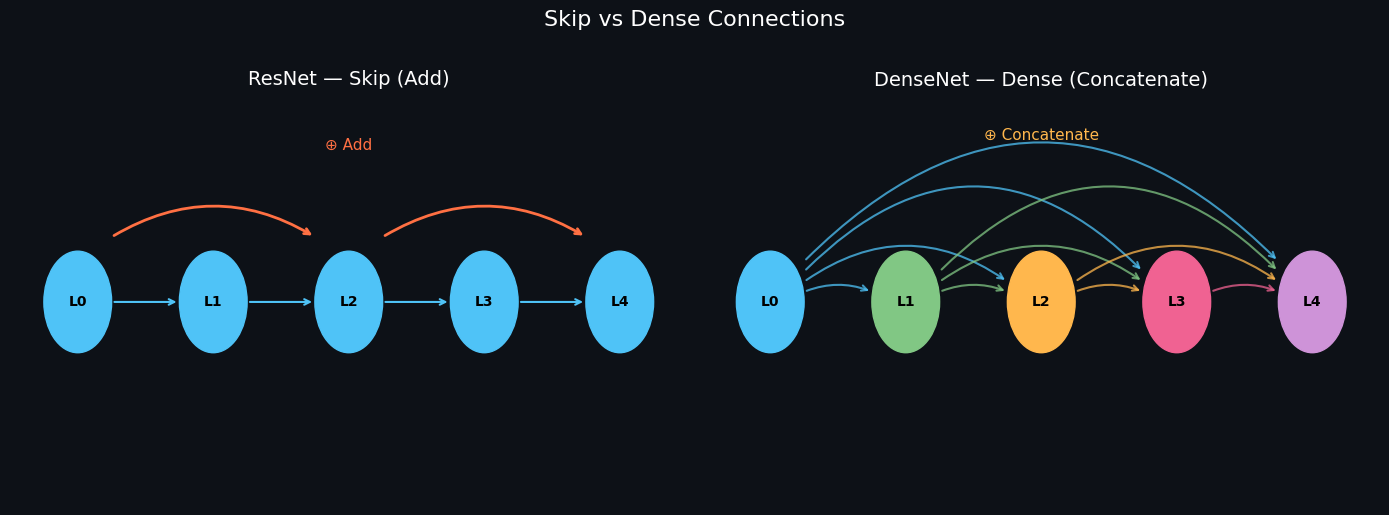

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0d1117')

for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.set_xlim(-0.5, 4.5)
    ax.set_ylim(-0.5, 1.5)
    ax.axis('off')

nodes = [0, 1, 2, 3, 4]

# ── ResNet ──
ax = axes[0]
ax.set_title('ResNet — Skip (Add)', color='white', fontsize=14, pad=10)
for x in nodes:
    ax.add_patch(plt.Circle((x, 0.5), 0.25, color='#4fc3f7', zorder=3))
    ax.text(x, 0.5, f'L{x}', ha='center', va='center', color='black', fontweight='bold', fontsize=10)
for i in range(4):
    ax.annotate('', xy=(i+0.75, 0.5), xytext=(i+0.25, 0.5),
                arrowprops=dict(arrowstyle='->', color='#4fc3f7', lw=1.5))
for s, e in [(0, 2), (2, 4)]:
    ax.annotate('', xy=(e-0.25, 0.82), xytext=(s+0.25, 0.82),
                arrowprops=dict(arrowstyle='->', color='#ff7043', lw=2,
                                connectionstyle='arc3,rad=-0.3'))
ax.text(2, 1.25, '⊕ Add', ha='center', color='#ff7043', fontsize=11)

# ── DenseNet ──
ax = axes[1]
ax.set_title('DenseNet — Dense (Concatenate)', color='white', fontsize=14, pad=10)
dense_colors = ['#4fc3f7', '#81c784', '#ffb74d', '#f06292', '#ce93d8']
for x, c in zip(nodes, dense_colors):
    ax.add_patch(plt.Circle((x, 0.5), 0.25, color=c, zorder=3))
    ax.text(x, 0.5, f'L{x}', ha='center', va='center', color='black', fontweight='bold', fontsize=10)
arcs = [0.2, 0.35, 0.5]
for end in range(1, 5):
    for start in range(end):
        rad = -arcs[min(end - start - 1, 2)]
        ax.annotate('', xy=(end-0.25, 0.5+0.05*(end-start)),
                    xytext=(start+0.25, 0.5+0.05*(end-start)),
                    arrowprops=dict(arrowstyle='->', color=dense_colors[start], lw=1.5,
                                    connectionstyle=f'arc3,rad={rad}', alpha=0.75))
ax.text(2, 1.3, '⊕ Concatenate', ha='center', color='#ffb74d', fontsize=11)

plt.suptitle('Skip vs Dense Connections', color='white', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('dense_connections.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

In [ ]:
# DATA_DIR is now set by the previous cell (611eb562) after downloading with kagglehub
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

# ImageNet normalization
def preprocess(x):
    return tf.keras.applications.densenet.preprocess_input(x)

# Data augmentation for training
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess,
    horizontal_flip=True,
    rotation_range=10,
    brightness_range=[0.8, 1.2],
    zoom_range=0.1,
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess)

train_gen = train_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'train'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
)

val_gen = val_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'val'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

test_gen = val_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

CLASSES = list(train_gen.class_indices.keys())
print(f'Classes: {CLASSES}')
print(f'Train: {train_gen.samples} | Val: {val_gen.samples} | Test: {test_gen.samples}')


NameError: name 'DATA_DIR' is not defined

In [ ]:
import os

# Install kagglehub client
!pip install kagglehub

# Create .kaggle directory if it doesn't exist (less critical for kagglehub, but good practice)
!mkdir -p ~/.kaggle


In [ ]:
import kagglehub
import os

# Download the dataset using kagglehub
# This downloads and extracts the dataset, returning the path to the root of the extracted files.
download_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

# Find the 'chest_xray' directory within the downloaded content
global DATA_DIR # Declare DATA_DIR as global so it can be used in other cells
DATA_DIR = None
for root, dirs, files in os.walk(download_path):
    if 'chest_xray' in dirs:
        DATA_DIR = os.path.join(root, 'chest_xray')
        break

if DATA_DIR:
    print(f'Dataset downloaded to: {download_path}')
    print(f'DATA_DIR set to: {DATA_DIR}')
    # Verify the directory structure
    print('\nVerifying directory structure:')
    !ls {DATA_DIR}
    !ls {os.path.join(DATA_DIR, 'train')}
else:
    print('Error: Could not find chest_xray directory within the downloaded dataset.')


100%|██████████| 2.29G/2.29G [00:26<00:00, 92.8MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2
DATA_DIR set to: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray

Verifying directory structure:
chest_xray  __MACOSX  test  train  val
NORMAL	PNEUMONIA


In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [ ]:
DATA_DIR = '/kaggle/input/chest-xray-pneumonia/chest_xray' # Explicitly set DATA_DIR to the correct path
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

# ImageNet normalization
def preprocess(x):
    return tf.keras.applications.densenet.preprocess_input(x)

# Data augmentation for training
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess,
    horizontal_flip=True,
    rotation_range=10,
    brightness_range=[0.8, 1.2],
    zoom_range=0.1,
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess)

train_gen = train_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'train'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
)

val_gen = val_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'val'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

test_gen = val_datagen.flow_from_directory(
    os.path.join(DATA_DIR, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

CLASSES = list(train_gen.class_indices.keys())
print(f'Classes: {CLASSES}')
print(f'Train: {train_gen.samples} | Val: {val_gen.samples} | Test: {test_gen.samples}')

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Train: 5216 | Val: 16 | Test: 624


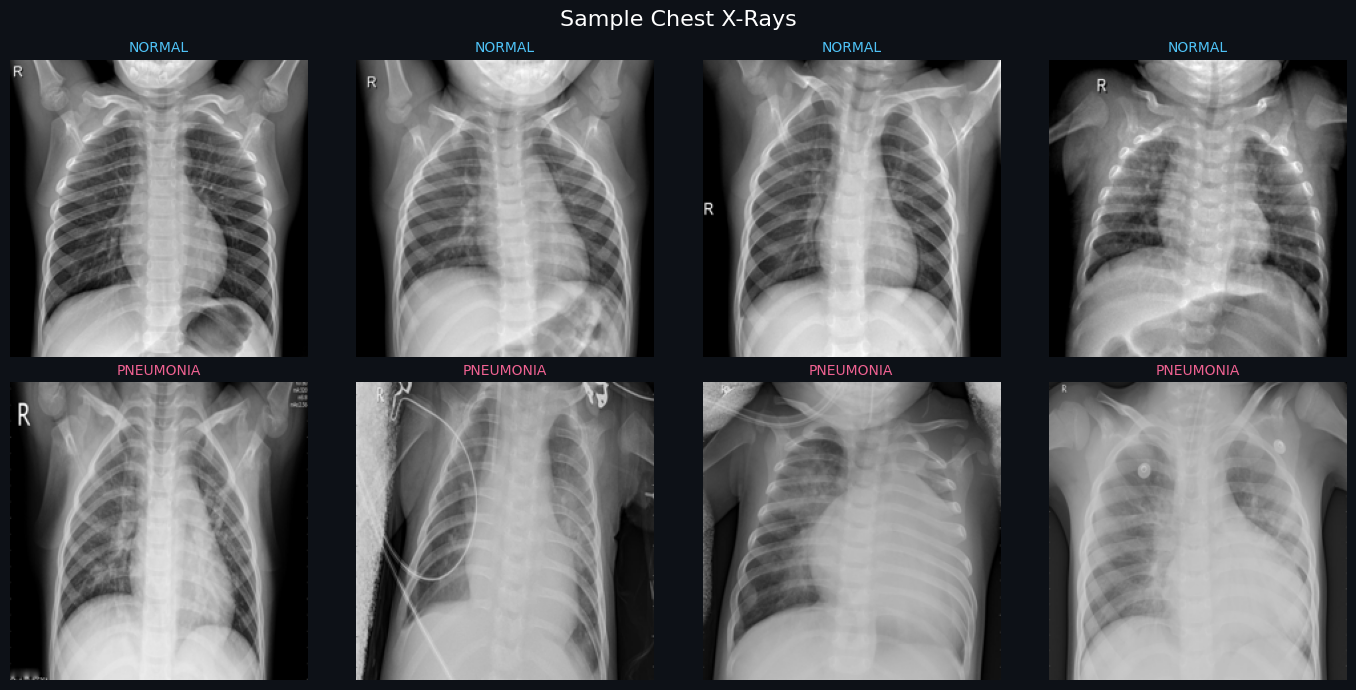

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Sample Chest X-Rays', color='white', fontsize=16)

label_to_color = {'NORMAL': '#4fc3f7', 'PNEUMONIA': '#f06292'}

for cls_idx, cls_name in enumerate(CLASSES):
    cls_dir = os.path.join(DATA_DIR, 'train', cls_name)
    files = random.sample(os.listdir(cls_dir), 4)
    for col, fname in enumerate(files):
        img = Image.open(os.path.join(cls_dir, fname)).convert('RGB').resize(IMG_SIZE)
        ax = axes[cls_idx][col]
        ax.imshow(np.array(img), cmap='gray')
        ax.set_title(cls_name, color=label_to_color.get(cls_name, 'white'), fontsize=10)
        ax.axis('off')
        ax.set_facecolor('#0d1117')

plt.tight_layout()
plt.show()

In [ ]:
# Load DenseNet-121 pretrained on ImageNet, exclude top classifier
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,         # remove ImageNet head
    input_shape=(*IMG_SIZE, 3)
)

# Freeze pretrained weights initially
base_model.trainable = False

# Build new classifier head for binary task
inputs  = keras.Input(shape=(*IMG_SIZE, 3))
x       = base_model(inputs, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.4)(x)
x       = layers.Dense(256, activation='relu')(x)
x       = layers.Dropout(0.2)(x)
outputs = layers.Dense(2, activation='softmax')(x)   # NORMAL vs PNEUMONIA

model = keras.Model(inputs, outputs, name='DenseNet121_XRay')
model.summary(line_length=80)

print(f'\nTotal params:     {model.count_params():,}')
print(f'Trainable params: {sum([tf.size(w).numpy() for w in model.trainable_weights]):,}')

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_XRay"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)        │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ densenet121 (Functional)          │ (None, 7, 7, 1024)       │     7,037,504 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d_1        │ (None, 1024)             │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 1024)             │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 256)              │       262,400 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_1 (Dropout)               │ (None, 256)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 2)                │           514 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 7,300,418 (27.85 MB)

 Trainable params: 262,914 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)


Total params:     7,300,418
Trainable params: 262,914


In [ ]:
# Compute class weights to handle NORMAL/PNEUMONIA imbalance
counts      = np.bincount(train_gen.classes)
total       = sum(counts)
class_weight = {i: total / (len(counts) * c) for i, c in enumerate(counts)}
print(f'Class weights: {class_weight}')

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb_checkpoint = callbacks.ModelCheckpoint(
    'best_densenet_xray.keras', save_best_only=True,
    monitor='val_accuracy', verbose=1
)
cb_early = callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_accuracy')

print('\n── Phase 1: Training head (backbone frozen) ──')
history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    class_weight=class_weight,
    callbacks=[cb_checkpoint, cb_early],
)

Class weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}

── Phase 1: Training head (backbone frozen) ──
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9043 - loss: 0.2348
Epoch 1: val_accuracy improved from None to 0.93750, saving model to best_densenet_xray.keras

Epoch 1: finished saving model to best_densenet_xray.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 984s 6s/step - accuracy: 0.9093 - loss: 0.2215 - val_accuracy: 0.9375 - val_loss: 0.1287
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9198 - loss: 0.2072
Epoch 2: val_accuracy did not improve from 0.93750
163/163 ━━━━━━━━━━━━━━━━━━━━ 942s 6s/step - accuracy: 0.9149 - loss: 0.2123 - val_accuracy: 0.9375 - val_loss: 0.1274
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9105 - loss: 0.2136
Epoch 3: val_accuracy did not improve from 0.93750
163/163 ━━━━━━━━━━━━━━━━━━━━ 943s 6s/step - accuracy: 0.9178 - loss: 0.1980 - val_accuracy: 0.9375 - val_loss: 0.1295
Epoc

##  Phase 2 — Fine-Tune (unfreeze last DenseBlock)

In [ ]:
# Unfreeze the last dense block of DenseNet-121
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = 'pool5' in layer.name or 'conv5' in layer.name

trainable_now = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f'Trainable params after unfreeze: {trainable_now:,}')

# Lower LR for fine-tuning
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, verbose=1
)

print('\n── Phase 2: Fine-tuning (last DenseBlock unfrozen) ──')
history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    class_weight=class_weight,
    callbacks=[cb_checkpoint, cb_early, cb_reduce_lr],
)

Trainable params after unfreeze: 2,420,994

── Phase 2: Fine-tuning (last DenseBlock unfrozen) ──
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8885 - loss: 0.3803
Epoch 1: val_accuracy did not improve from 0.93750
163/163 ━━━━━━━━━━━━━━━━━━━━ 1085s 6s/step - accuracy: 0.8955 - loss: 0.2771 - val_accuracy: 0.9375 - val_loss: 0.1207 - learning_rate: 1.0000e-05
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9135 - loss: 0.2037
Epoch 2: val_accuracy improved from 0.93750 to 1.00000, saving model to best_densenet_xray.keras

Epoch 2: finished saving model to best_densenet_xray.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 1060s 6s/step - accuracy: 0.9170 - loss: 0.1946 - val_accuracy: 1.0000 - val_loss: 0.0785 - learning_rate: 1.0000e-05
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9267 - loss: 0.1734
Epoch 3: val_accuracy did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 1070s 7s/step - accuracy: 0.9283 - loss: 0.1747 - val_accuracy: 1.00

##  Training Curves

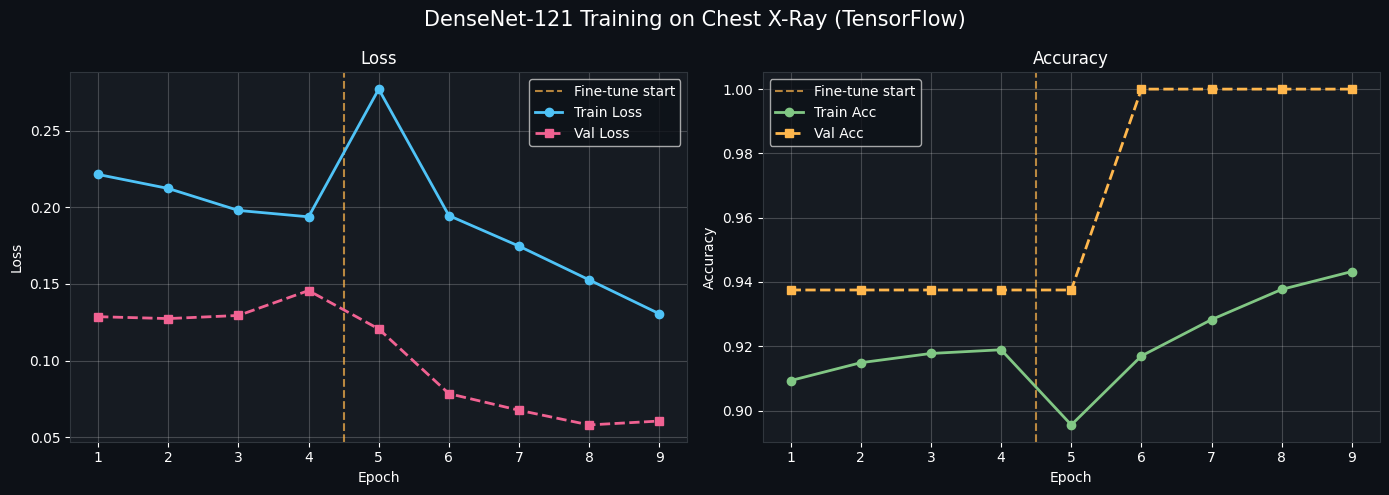

In [ ]:
# Merge both phases
def merge(h1, h2, key):
    return h1.history.get(key, []) + h2.history.get(key, [])

train_acc  = merge(history1, history2, 'accuracy')
val_acc    = merge(history1, history2, 'val_accuracy')
train_loss = merge(history1, history2, 'loss')
val_loss   = merge(history1, history2, 'val_loss')
epochs     = range(1, len(train_acc) + 1)
phase_split = len(history1.history['accuracy'])  # where phase 2 starts

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0d1117')

for ax in [ax1, ax2]:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    ax.title.set_color('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#30363d')
    ax.axvline(phase_split + 0.5, color='#ffb74d', linestyle='--', alpha=0.7, label='Fine-tune start')

ax1.plot(epochs, train_loss, 'o-', color='#4fc3f7', label='Train Loss', lw=2)
ax1.plot(epochs, val_loss,   's--', color='#f06292', label='Val Loss',   lw=2)
ax1.set_title('Loss'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.legend(facecolor='#0d1117', labelcolor='white'); ax1.grid(alpha=0.2, color='white')

ax2.plot(epochs, train_acc, 'o-', color='#81c784', label='Train Acc', lw=2)
ax2.plot(epochs, val_acc,   's--', color='#ffb74d', label='Val Acc',   lw=2)
ax2.set_title('Accuracy'); ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(facecolor='#0d1117', labelcolor='white'); ax2.grid(alpha=0.2, color='white')

plt.suptitle('DenseNet-121 Training on Chest X-Ray (TensorFlow)', color='white', fontsize=15)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

##  Test Evaluation + Confusion Matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 115s 5s/step - accuracy: 0.8910 - loss: 0.2613

Test Accuracy: 0.8910 | Test Loss: 0.2613
20/20 ━━━━━━━━━━━━━━━━━━━━ 115s 5s/step

── Classification Report ──
              precision    recall  f1-score   support

      NORMAL       0.89      0.81      0.85       234
   PNEUMONIA       0.89      0.94      0.92       390

    accuracy                           0.89       624
   macro avg       0.89      0.87      0.88       624
weighted avg       0.89      0.89      0.89       624



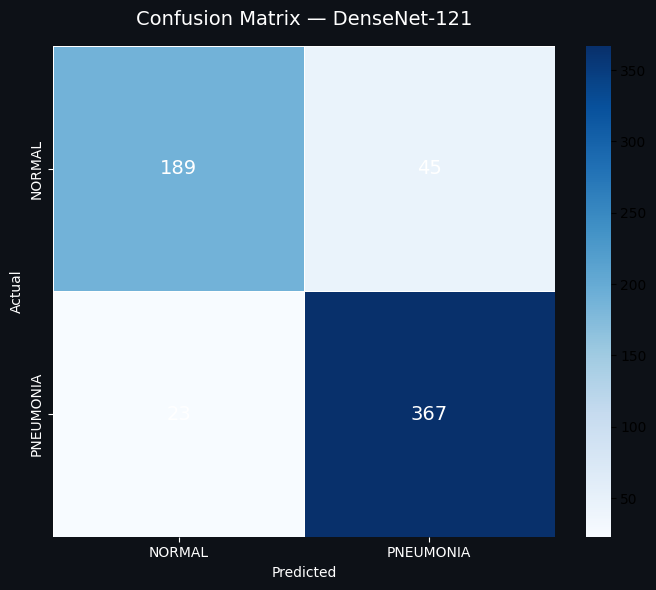

In [ ]:
# Load best saved model
model = keras.models.load_model('best_densenet_xray.keras')

# Evaluate
test_loss, test_acc = model.evaluate(test_gen, verbose=1)
print(f'\nTest Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}')

# Predictions
test_gen.reset()
preds      = model.predict(test_gen, verbose=1)
pred_labels = np.argmax(preds, axis=1)
true_labels = test_gen.classes

print('\n── Classification Report ──')
print(classification_report(true_labels, pred_labels, target_names=CLASSES))

# Confusion matrix
cm = confusion_matrix(true_labels, pred_labels)

fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#0d1117')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=0.5, ax=ax, annot_kws={'size': 14, 'color': 'white'})

ax.set_title('Confusion Matrix — DenseNet-121', color='white', fontsize=14, pad=15)
ax.set_xlabel('Predicted', color='white')
ax.set_ylabel('Actual', color='white')
ax.tick_params(colors='white')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

##  Predict on a Single X-Ray Image

True label: PNEUMONIA


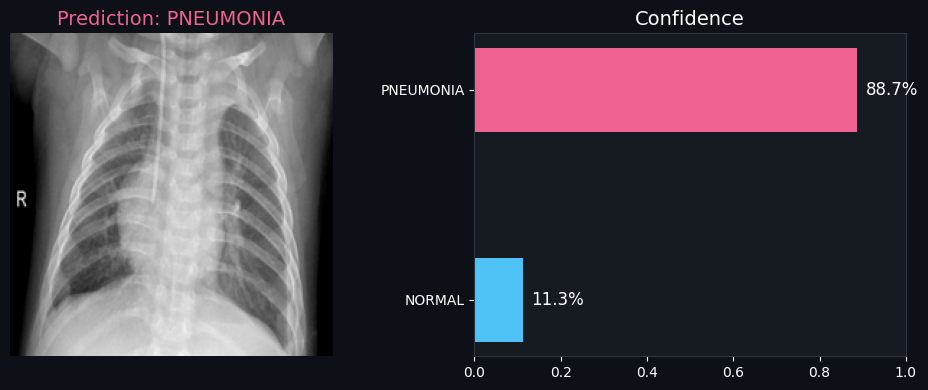

Predicted:  PNEUMONIA (confidence: 88.7%)


In [ ]:
def predict_xray(image_path, model, classes, img_size=(224, 224)):
    """Predict a single X-ray and visualize confidence scores."""
    img = Image.open(image_path).convert('RGB').resize(img_size)
    arr = np.array(img, dtype=np.float32)
    arr = tf.keras.applications.densenet.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)   # add batch dim

    probs = model.predict(arr, verbose=0)[0]
    pred  = np.argmax(probs)
    label = classes[pred]
    color = '#81c784' if label == 'NORMAL' else '#f06292'

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    fig.patch.set_facecolor('#0d1117')

    ax1.imshow(np.array(Image.open(image_path).convert('RGB').resize(img_size)), cmap='gray')
    ax1.set_title(f'Prediction: {label}', color=color, fontsize=14)
    ax1.axis('off'); ax1.set_facecolor('#0d1117')

    bar_colors = ['#4fc3f7', '#f06292']
    bars = ax2.barh(classes, probs, color=bar_colors, height=0.4)
    ax2.set_xlim(0, 1)
    ax2.set_title('Confidence', color='white', fontsize=14)
    ax2.set_facecolor('#161b22')
    ax2.tick_params(colors='white')
    for spine in ax2.spines.values(): spine.set_edgecolor('#30363d')
    for bar, prob in zip(bars, probs):
        ax2.text(prob + 0.02, bar.get_y() + bar.get_height()/2,
                 f'{prob*100:.1f}%', va='center', color='white', fontsize=12)

    plt.tight_layout()
    plt.show()
    return label, probs


# ── Example usage ──
# Pick a random test image
sample_class = random.choice(CLASSES)
sample_dir   = os.path.join(DATA_DIR, 'test', sample_class)
sample_file  = random.choice(os.listdir(sample_dir))
sample_path  = os.path.join(sample_dir, sample_file)

print(f'True label: {sample_class}')
pred_label, probs = predict_xray(sample_path, model, CLASSES)
print(f'Predicted:  {pred_label} (confidence: {max(probs)*100:.1f}%)')

##  Why DenseNet for Medical Imaging?

| Property | Benefit in Medical Imaging |
|---|---|
| Dense connections | Preserves fine-grained spatial features (lung opacity, nodules) |
| Feature reuse | Fewer parameters → less overfitting on small medical datasets |
| Deep supervision | Gradients flow to early layers directly → no vanishing gradient |
| Growth rate k | Hyperparameter controls model size precisely |

**Real-world use:** CheXNet (Stanford, 2017) used DenseNet-121 to detect 14 pathologies from chest X-rays, surpassing radiologist-level performance on pneumonia.

---
### Summary
```
MiniDenseNet built from scratch (Keras functional API)  ✅
DenseNet-121 pretrained fine-tuned (2-phase)            ✅
Chest X-Ray Pneumonia classification                    ✅
Visualization + Confusion Matrix                        ✅
Single image inference with confidence bars             ✅
```

### Loading and using the saved model

Model loaded successfully!
True label: NORMAL


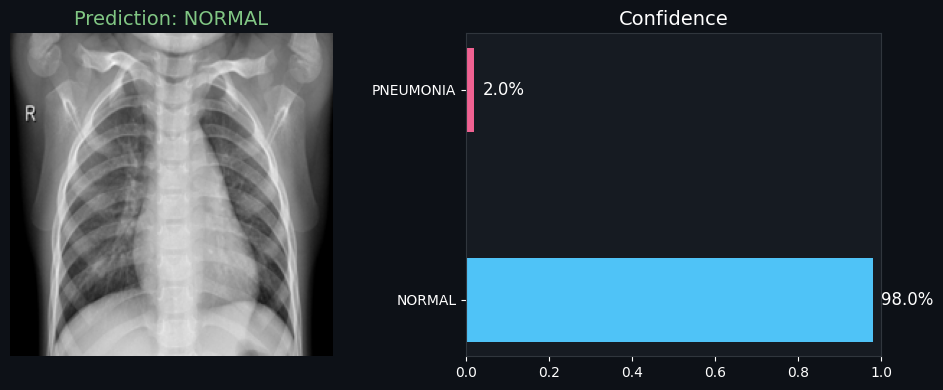

Predicted:  NORMAL (confidence: 98.0%)


In [ ]:
import tensorflow as tf
from tensorflow import keras
import os
import numpy as np
from PIL import Image
import random

# Assuming DATA_DIR, CLASSES, and IMG_SIZE are already defined from previous cells
# If starting a fresh session, you might need to re-run the data loading and definition cells for these variables.

# Load the best saved model
loaded_model = keras.models.load_model('best_densenet_xray.keras')
print("Model loaded successfully!")

# Define the predict_xray function again if this is a fresh session
def predict_xray(image_path, model, classes, img_size=(224, 224)):
    """Predict a single X-ray and visualize confidence scores."""
    img = Image.open(image_path).convert('RGB').resize(img_size)
    arr = np.array(img, dtype=np.float32)
    arr = tf.keras.applications.densenet.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)   # add batch dim

    probs = model.predict(arr, verbose=0)[0]
    pred  = np.argmax(probs)
    label = classes[pred]
    color = '#81c784' if label == 'NORMAL' else '#f06292'

    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    fig.patch.set_facecolor('#0d1117')

    ax1.imshow(np.array(Image.open(image_path).convert('RGB').resize(img_size)), cmap='gray')
    ax1.set_title(f'Prediction: {label}', color=color, fontsize=14)
    ax1.axis('off'); ax1.set_facecolor('#0d1117')

    bar_colors = ['#4fc3f7', '#f06292']
    bars = ax2.barh(classes, probs, color=bar_colors, height=0.4)
    ax2.set_xlim(0, 1)
    ax2.set_title('Confidence', color='white', fontsize=14)
    ax2.set_facecolor('#161b22')
    ax2.tick_params(colors='white')
    for spine in ax2.spines.values(): spine.set_edgecolor('#30363d')
    for bar, prob in zip(bars, probs):
        ax2.text(prob + 0.02, bar.get_y() + bar.get_height()/2,
                 f'{prob*100:.1f}%', va='center', color='white', fontsize=12)

    plt.tight_layout()
    plt.show()
    return label, probs

# Example usage with the loaded model
# Pick a random test image
sample_class = random.choice(CLASSES)
sample_dir   = os.path.join(DATA_DIR, 'test', sample_class)
sample_file  = random.choice(os.listdir(sample_dir))
sample_path  = os.path.join(sample_dir, sample_file)

print(f'True label: {sample_class}')
pred_label, probs = predict_xray(sample_path, loaded_model, CLASSES)
print(f'Predicted:  {pred_label} (confidence: {max(probs)*100:.1f}%)')

### 💾 Download the Trained Model to Your Local Device

In [ ]:
from google.colab import files
import os

model_filename = 'best_densenet_xray.keras'

if os.path.exists(model_filename):
    print(f"Triggering download for {model_filename}... Please wait.")
    files.download(model_filename)
else:
    print(f"Error: {model_filename} not found in the current workspace. Please ensure your training cells ran successfully!")